In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs

# Generate a synthetic dataset with 1,000 samples, 4 features, and 4 true centers
X_raw, y_true = make_blobs(
    n_samples=1000,
    n_features=4,
    centers=4,
    cluster_std=1.2,
    random_state=42
)

# Convert to DataFrame for easy handling
feature_names = ['Feature_1', 'Feature_2', 'Feature_3', 'Feature_4']
df = pd.DataFrame(X_raw, columns=feature_names)

print("Dataset Head:")
df.head()

Dataset Head:


,Feature_1,Feature_2,Feature_3,Feature_4
0,-8.496179,-8.046046,-7.397831,6.535250
1,-5.530692,-5.743078,-9.765781,7.811986
2,-3.051965,6.105631,2.739195,2.885667
3,-2.197338,9.952474,3.155538,0.388622
4,-5.684370,-7.788264,-10.544501,9.125123


In [2]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

print(f"Scaled Data Shape: {X_scaled.shape}")

Scaled Data Shape: (1000, 4)


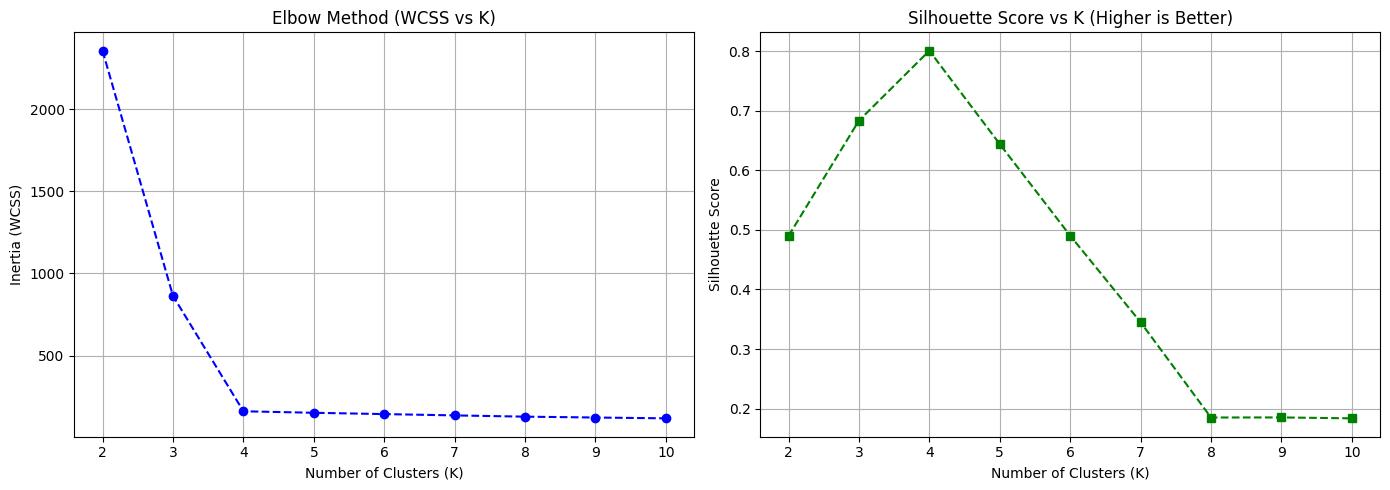

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

wcss = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)

    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Plot Elbow Method and Silhouette Scores side-by-side
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 1. Elbow Curve
ax[0].plot(k_range, wcss, marker='o', color='b', linestyle='--')
ax[0].set_title('Elbow Method (WCSS vs K)')
ax[0].set_xlabel('Number of Clusters (K)')
ax[0].set_ylabel('Inertia (WCSS)')
ax[0].grid(True)

# 2. Silhouette Score Plot
ax[1].plot(k_range, silhouette_scores, marker='s', color='green', linestyle='--')
ax[1].set_title('Silhouette Score vs K (Higher is Better)')
ax[1].set_xlabel('Number of Clusters (K)')
ax[1].set_ylabel('Silhouette Score')
ax[1].grid(True)

plt.tight_layout()
plt.show()

In [4]:
# Set optimal K based on evaluation
optimal_k = 4

kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', n_init=10, random_state=42)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

print("Sample counts per cluster:")
print(df['Cluster'].value_counts())

Sample counts per cluster:
Cluster
3    250
2    250
0    250
1    250
Name: count, dtype: int64


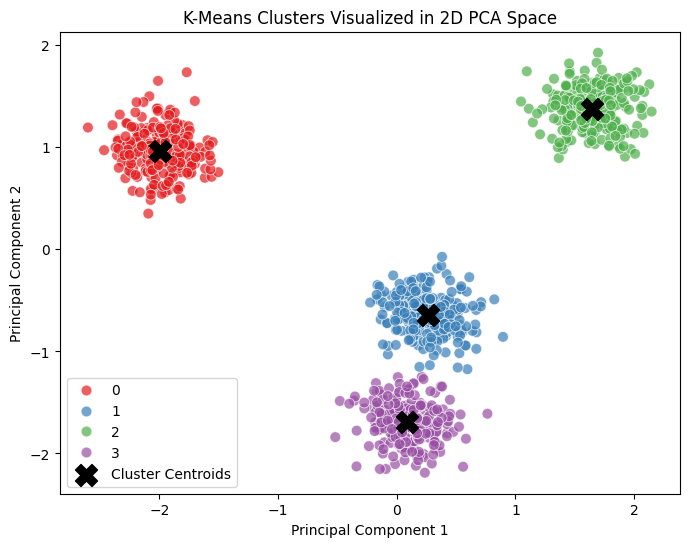

In [5]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(kmeans_final.cluster_centers_)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['Cluster'],
    palette='Set1',
    s=60,
    alpha=0.7
)

# Plot Centroids
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    s=250,
    c='black',
    marker='X',
    label='Cluster Centroids'
)

plt.title('K-Means Clusters Visualized in 2D PCA Space')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()

In [6]:
# Unscale cluster centroids to original feature values
unscaled_centroids = scaler.inverse_transform(kmeans_final.cluster_centers_)
centroid_df = pd.DataFrame(unscaled_centroids, columns=feature_names)
centroid_df.index.name = 'Cluster'

print("=== CLUSTER CENTROIDS (Feature Averages per Cluster) ===")
centroid_df.round(2)

=== CLUSTER CENTROIDS (Feature Averages per Cluster) ===


,Feature_1,Feature_2,Feature_3,Feature_4
Cluster,,,,
0,6.75,-5.86,-6.52,-6.28
1,1.99,4.23,-9.56,9.38
2,-2.51,9.03,4.67,2.03
3,-6.82,-6.74,-8.79,7.36


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


=== ANN MODEL SUMMARY ===


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,217 (4.75 KB)

 Trainable params: 1,217 (4.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.5375 - loss: 0.7242 - val_accuracy: 0.6938 - val_loss: 0.6212
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6438 - loss: 0.6268 - val_accuracy: 0.7063 - val_loss: 0.5686
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6625 - loss: 0.5941 - val_accuracy: 0.7312 - val_loss: 0.5316
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7188 - loss: 0.5565 - val_accuracy: 0.7500 - val_loss: 0.5047
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7469 - loss: 0.5200 - val_accuracy: 0.7625 - val_loss: 0.4824
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.7422 - loss: 0.4981 - val_accuracy: 0.7875 - val_loss: 0.4626
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7703 - loss: 0.4703 - val_accuracy: 0.8000 - val_loss: 0.4462
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8062 - loss: 0.4419 - val_accuracy: 0.8062 - val_

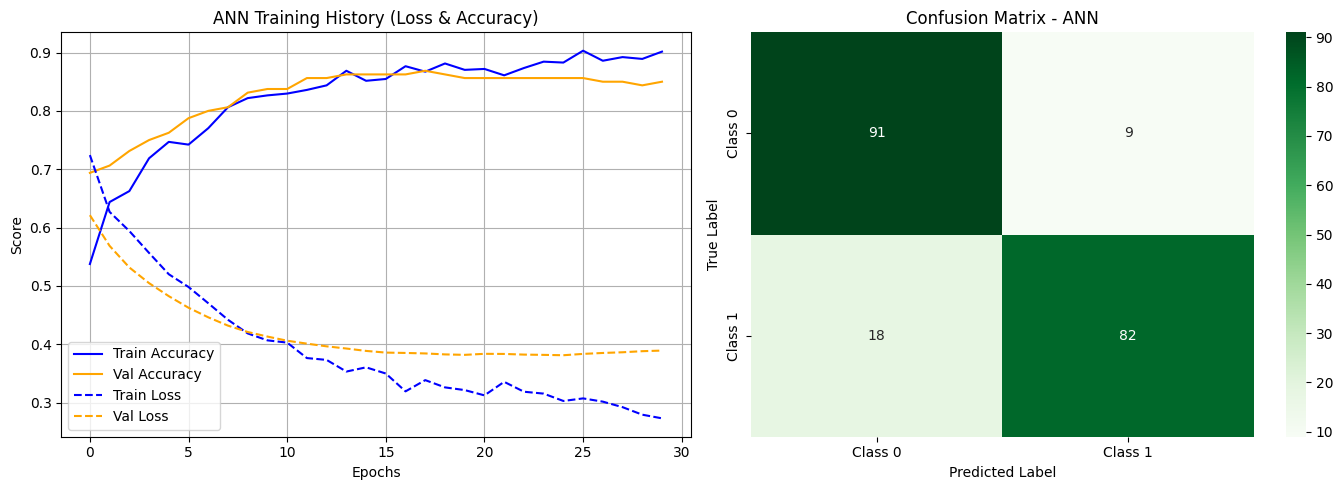


=== ANN Test Accuracy: 86.50% ===

=== Detailed Classification Report ===
              precision    recall  f1-score   support

           0       0.83      0.91      0.87       100
           1       0.90      0.82      0.86       100

    accuracy                           0.86       200
   macro avg       0.87      0.86      0.86       200
weighted avg       0.87      0.86      0.86       200



In [7]:
#ANN
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Set random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# --- 1. DATA CHECK & PREPARATION ---
if 'X_train_scaled' in globals() and 'y_train' in globals():
    X_tr, X_te, y_tr, y_te = X_train_scaled, X_test_scaled, y_train, y_test
else:
    # Generate synthetic dataset if variables are not in active memory
    X, y = make_classification(n_samples=1000, n_features=20, n_classes=2, random_state=42)
    X_tr_raw, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_tr_raw)
    X_te = scaler.transform(X_te)

# --- 2. BUILD THE ANN ARCHITECTURE ---
input_dim = X_tr.shape[1]

ann_model = Sequential([
    # Input & First Hidden Layer
    Dense(units=32, activation='relu', input_dim=input_dim),
    Dropout(0.2),  # Prevents overfitting

    # Second Hidden Layer
    Dense(units=16, activation='relu'),
    Dropout(0.2),

    # Output Layer (Sigmoid for binary classification: outputs probability between 0 and 1)
    Dense(units=1, activation='sigmoid')
])

# --- 3. COMPILE MODEL ---
ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("=== ANN MODEL SUMMARY ===")
ann_model.summary()

# --- 4. TRAIN MODEL ---
history = ann_model.fit(
    X_tr, y_tr,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# --- 5. EVALUATE & PREDICT ---
# Predict probabilities
y_probs = ann_model.predict(X_te).ravel()

# Convert probabilities to binary class labels (Threshold = 0.5)
y_pred_ann = (y_probs >= 0.5).astype(int)

# --- 6. PERFORMANCE VISUALIZATIONS ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Loss & Accuracy Curves across Epochs
axes[0].plot(history.history['accuracy'], label='Train Accuracy', color='blue')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy', color='orange')
axes[0].plot(history.history['loss'], label='Train Loss', color='blue', linestyle='--')
axes[0].plot(history.history['val_loss'], label='Val Loss', color='orange', linestyle='--')
axes[0].set_title('ANN Training History (Loss & Accuracy)')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Score')
axes[0].legend()
axes[0].grid(True)

# Plot 2: Confusion Matrix
cm = confusion_matrix(y_te, y_pred_ann)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'])
axes[1].set_title('Confusion Matrix - ANN')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

# --- 7. METRICS OUTPUT ---
accuracy = accuracy_score(y_te, y_pred_ann)
print(f"\n=== ANN Test Accuracy: {accuracy * 100:.2f}% ===")
print("\n=== Detailed Classification Report ===")
print(classification_report(y_te, y_pred_ann))